# Прогноз времени до следующего заключения (free → jail)


- **момент отсчёта** — выход из заключения (состояние free);
- **повторное событие** — вход в любое следующее заключение (jail или prison), **OldCase тоже событие**;

Вход — файлы ноутбука `этапы_по_обвинениям.ipynb` (этап 0) в папке `данные_этапы_по_обвинениям/`. 
Вывод — в `данные_этапы_по_обвинениям/free-jail/`.

## 1. Данные: эпизоды свободы

Одна строка `event_table` — один эпизод заключения (переводы jail ↔ prison уже склеены в эпизод на этапе 0.13). Эпизод свободы начинается в день выхода из эпизода заключения:

- **T** — дней от выхода до входа в следующее заключение человека (`gap_next`); если следующего заключения нет — дней до конца наблюдения 01.04.2016 (`followup_days`);
- **E** — 1, если следующее заключение было (любое, включая OldCase), 0 — цензура;
- **state** — основной тип только что закончившегося заключения (самый тяжёлый, вариант B); нужен для графовых признаков в шаге 3;
- **next_reason** — причина следующего заключения (только для описания, в модели не прогнозируется).

Не используются (как в этапе 2.1): эпизоды, где человек ещё сидит на конец наблюдения (выхода нет), и пересекающиеся заключения (следующий вход раньше выхода). Повторный вход в день выхода — `T = 0.5` дня.

### 1.1. Пути и загрузка

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

HERE = Path.cwd()                                         # папка ноутбука: <папка ноутбука>
SRC = HERE / "данные_этапы_по_обвинениям"                 # вход - этап 0 ноутбука этапы_по_обвинениям.ipynb
OUT = SRC / "free-jail"
OUT.mkdir(exist_ok=True)
STUDY_END = pd.Timestamp("2016-04-01")                    # конец наблюдения
SEED = 42

et = pd.read_csv(SRC / "event_table.csv", parse_dates=["in_custody", "out_custody"], low_memory=False)
print(f"event_table: {et.shape[0]} эпизодов заключения, {et['id'].nunique()} людей")

event_table: 21406 эпизодов заключения, 10433 людей


### 1.2. Таблица эпизодов свободы

In [2]:
# разбиение людей на обучение / тест (80 / 20) - как в «Этапы 1–3: подготовка» ноутбука этапы_по_обвинениям.ipynb
et = et.sort_values(["id", "in_custody", "ep_row", "step"]).reset_index(drop=True)
rng = np.random.default_rng(SEED)
people_ids = et["id"].unique()
test_ids = set(rng.choice(people_ids, size=int(0.2 * len(people_ids)), replace=False))

fr = et[["id", "ep_row", "event_idx", "n_events", "in_custody", "out_custody", "ongoing",
         "censored", "gap_next", "followup_days", "types_by_severity"]].copy()
fr["state"] = fr["types_by_severity"].str.split("+").str[0]          # основной тип заключения (вариант B)
fr["next_reason"] = et.groupby("id")["reason"].shift(-1)             # причина следующего заключения (описание)
fr["T"] = np.where(fr["censored"], fr["followup_days"], fr["gap_next"])
fr["E"] = (~fr["censored"]).astype(int)
fr["is_test"] = fr["id"].isin(test_ids)
fr["first_episode"] = fr["event_idx"] == 1                           # первый эпизод свободы человека в окне (для IAUC_RE)

n_all = len(fr)
drop_ongoing = fr["ongoing"]                                         # ещё сидит на 01.04.2016 - выхода нет
drop_overlap = ~drop_ongoing & (fr["T"] < 0)                         # следующий вход раньше выхода
same_day = ~drop_ongoing & (fr["T"] == 0)
fr = fr[~drop_ongoing & ~drop_overlap].copy()
fr["T"] = fr["T"].clip(lower=0.5)                                    # повторный вход в день выхода - полдня
fr = fr.drop(columns=["ongoing", "censored", "gap_next", "followup_days", "types_by_severity"]).reset_index(drop=True)

print(f"эпизодов заключения: {n_all}")
print(f"  убраны: ещё сидят на конец наблюдения - {int(drop_ongoing.sum())}, пересечения - {int(drop_overlap.sum())}")
print(f"  повторный вход в день выхода (T = 0.5) - {int(same_day.sum())}")
print(f"эпизодов свободы: {len(fr)}, людей: {fr['id'].nunique()}")
fr.head()

эпизодов заключения: 21406
  убраны: ещё сидят на конец наблюдения - 703, пересечения - 32
  повторный вход в день выхода (T = 0.5) - 56
эпизодов свободы: 20671, людей: 10329


,id,ep_row,event_idx,n_events,in_custody,out_custody,state,next_reason,T,E,is_test,first_episode
0,1,0,1,2,2013-08-13 06:03:42,2013-08-14 05:41:20,Violent,rearrest_old_case,327.0,1,False,True
1,1,1,2,2,2014-07-07 09:26:12,2014-07-14 08:24:15,OldCase,NaN,626.0,0,False,False
2,3,3,1,2,2013-01-26 03:45:27,2013-02-05 05:36:53,Violent,не привязано,981.0,1,False,True
3,3,4,2,2,2015-10-15 00:00:00,2015-12-07 00:00:00,Unknown,NaN,116.0,0,False,False
4,4,5,1,5,2013-04-13 04:58:34,2013-04-14 07:02:04,Drug,new_offense,63.0,1,False,True


### 1.3. Сводка: события, цензура, обучение / тест

In [3]:
def summary(d):
    return pd.Series({"эпизодов": len(d), "людей": d["id"].nunique(),
                      "событий (E = 1)": int(d["E"].sum()), "цензура (E = 0)": int((1 - d["E"]).sum()),
                      "доля событий": round(d["E"].mean(), 3),
                      "медиана T у событий, дней": d.loc[d["E"] == 1, "T"].median(),
                      "медиана T у цензуры, дней": d.loc[d["E"] == 0, "T"].median()})

summ = pd.DataFrame({"все": summary(fr), "обучение": summary(fr[~fr["is_test"]]), "тест": summary(fr[fr["is_test"]]),
                     "первый эпизод": summary(fr[fr["first_episode"]]),
                     "повторные эпизоды": summary(fr[~fr["first_episode"]])})
summ.to_csv(OUT / "1_summary.csv", encoding="utf-8-sig")
display(summ)

print("Причина следующего заключения (у событий):")
nr = fr.loc[fr["E"] == 1, "next_reason"].value_counts()
display(pd.DataFrame({"эпизодов": nr, "доля": (nr / nr.sum()).round(3)}))

print("Эпизодов свободы на человека:")
per = fr.groupby("id").size()
display(per.clip(upper=10).value_counts().sort_index().rename(index={10: "10+"}).to_frame("людей").T)

,все,обучение,тест,первый эпизод,повторные эпизоды
эпизодов,20671.000,16553.000,4118.00,10321.000,10350.000
людей,10329.000,8265.000,2064.00,10321.000,4921.000
событий (E = 1),10941.000,8758.000,2183.00,5130.000,5811.000
цензура (E = 0),9730.000,7795.000,1935.00,5191.000,4539.000
доля событий,0.529,0.529,0.53,0.497,0.561
"медиана T у событий, дней",124.000,123.000,128.00,167.000,97.000
"медиана T у цензуры, дней",632.000,635.000,620.00,804.000,380.000


Причина следующего заключения (у событий):


,эпизодов,доля
next_reason,,
new_offense,6760,0.618
rearrest_old_case,3559,0.325
не привязано,610,0.056
transfer_unlinked,12,0.001


Эпизодов свободы на человека:


,1,2,3,4,5,6,7,8,9,10+
людей,5410,2346,1219,666,345,150,84,40,33,36


### 1.4. Время до следующего заключения (Каплан–Мейер)

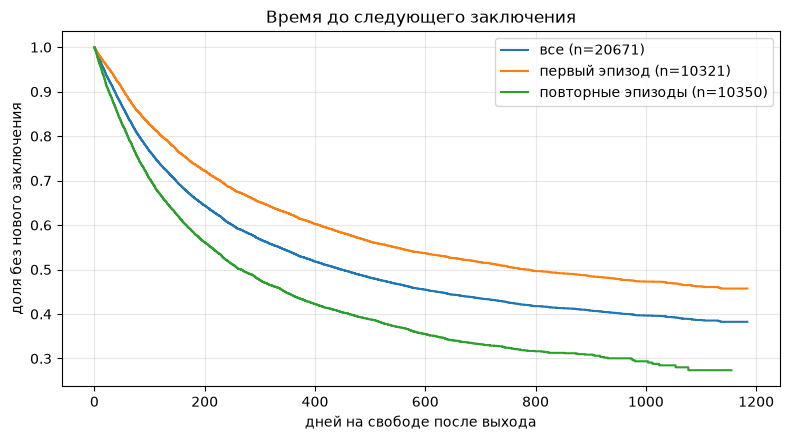

,S(30 дн.),S(90 дн.),S(180 дн.),S(365 дн.),S(730 дн.),"медиана, дней"
все,0.917,0.783,0.662,0.534,0.430,447.0
первый эпизод,0.945,0.839,0.738,0.619,0.511,785.0
повторные эпизоды,0.888,0.725,0.582,0.438,0.328,266.0


In [4]:
HORIZONS = [30, 90, 180, 365, 730]
fig, ax = plt.subplots(figsize=(8, 4.5))
km_tab = {}
for name, d in [("все", fr), ("первый эпизод", fr[fr["first_episode"]]), ("повторные эпизоды", fr[~fr["first_episode"]])]:
    km = KaplanMeierFitter().fit(d["T"], d["E"], label=f"{name} (n={len(d)})")
    km.plot_survival_function(ax=ax, ci_show=False)
    km_tab[name] = {**{f"S({h} дн.)": round(float(km.survival_function_at_times(h).iloc[0]), 3) for h in HORIZONS},
                    "медиана, дней": km.median_survival_time_}
ax.set_xlabel("дней на свободе после выхода"); ax.set_ylabel("доля без нового заключения")
ax.set_title("Время до следующего заключения"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "1_km.png", dpi=150); plt.show()

km_tab = pd.DataFrame(km_tab).T
km_tab.to_csv(OUT / "1_km.csv", encoding="utf-8-sig")
km_tab

### 1.5. Сохранение

In [5]:
fr.to_csv(OUT / "free_episodes.csv", index=False, encoding="utf-8-sig")
print(f"сохранено: {OUT / 'free_episodes.csv'}  ({fr.shape[0]} строк, столбцы: {', '.join(fr.columns)})")

сохранено: данные_этапы_по_обвинениям\free-jail\free_episodes.csv  (20671 строк, столбцы: id, ep_row, event_idx, n_events, in_custody, out_custody, state, next_reason, T, E, is_test, first_episode)


## 2. Наборы признаков



| Признак | Как считается |
|---|---|
| `episode_col` | номер заключения человека в окне (`event_idx`) |
| `first_custody` | 1 — прошлых заключений в окне нет (агрегаты истории тогда равны 0) |
| `age` | возраст на дату выхода |
| `male` | 1 — мужчина |
| `race_AfricanAmerican`, `race_Hispanic`, `race_Other` | раса; опорная — Caucasian, Asian и Native American отнесены к Other (как в `этапы_по_обвинениям.ipynb`, 3.1) |
| `deg_F1_F2`, `deg_F_other`, `deg_M1`, `deg_M2_MO3`, `deg_none` | укрупнённая самая тяжёлая степень обвинения текущего заключения (`deg_rank`): F1–F2, прочие felony (F5–F7), M1, M2 и MO3, нет степени (гражданские нарушения и заключения без обвинений); опорная — F3, самая частая |
| `time_since_last_arrest` | дней от последнего ареста **до** текущего заключения (раньше дня входа − 1) до выхода `t0`; ареста нет — медиана обучения и флаг `no_prior_arrest` |
| `curr_dur_custody` | дней в текущем заключении (`dur`); в модель идёт только через производные |
| `{f}_min`, `{f}_max`, `{f}_mean` | min / max / среднее по прошлым заключениям для `curr_dur_custody` и `time_since_last_arrest`; нет прошлых заключений — 0 (и `first_custody` = 1); прошлые заключения есть, но арестов перед ними не было — медиана обучения и флаг `no_arrest_in_history` |
| `log_curr_dur_custody` | log(1 + длительность текущего заключения) |
| `dur_deviation_from_avg` | длительность − средняя прошлая длительность (без истории — равна длительности) |
| `custody_increasing` | 1 — текущее заключение длиннее предыдущего; без истории — 0 |
| `arrest_speed_trend` | разность `time_since_last_arrest` с прошлым заключением; без истории — 0 |
| **RFM+ (2.2а)** | |
| `log_n_arrests_since_prev` | log(1 + арестов с прошлого заключения): аресты «человек + день» после дня выхода из прошлого заключения (у первого — после 01.01.2013) и раньше дня входа − 1 |
| `log_n_charges_since_prev` | log(1 + обвинений с прошлого заключения) в том же промежутке по дате, когда обвинение известно: дело с арестом — первый арест по делу, дело без ареста — дата правонарушения. Обвинения текущего дела и дел, арестованных после выхода, не считаются |
| `case_old`, `case_mixed` | тип узла: только старое дело (OldCase), новое + старое дело; опорная — новое дело. Не привязанные заключения отдельным признаком не идут: они почти все уже отмечены `deg_none` |
| `had_transfer` | 1 — в заключении был перевод jail ↔ prison |

Наборы: **база** (возраст, пол, раса) → **RFM** → **RFM+** (RFM + промежуток и тип узла).

Пропуски есть только в давности ареста. Они заполняются медианой по обучению, а сам факт пропуска — отдельным флагом, по одному на шаблон пропусков (как в 1711). Заглушка −1 не используется: для Кокса это настоящее число, и оно искажает коэффициенты. Балл COMPAS не используется.

Ограничение: в наборах этого раздела история — только окно 2013+ (кроме давности последнего ареста, она может быть и до 2013). Признаки до 2013 года (аресты, обвинения, prison) — отдельно, в разделе 4.3.

### 2.1. Аресты и история заключений

In [6]:
import sqlite3
DB = HERE.parent / "compas.db"                            # копия базы ProPublica в корне jupyter lab
ENTRY_GUARD = pd.Timedelta(days=1)                        # арест за день до входа и позже - арест текущего заключения (как в 1711)

with sqlite3.connect(DB) as con:
    ar = pd.read_sql("select person_id, arrest_date from casearrest", con)
ar["last_arrest"] = pd.to_datetime(ar["arrest_date"], errors="coerce").dt.normalize()
ar = (ar.dropna(subset=["last_arrest"]).query("last_arrest < @STUDY_END")
        .rename(columns={"person_id": "id"}).drop_duplicates(["id", "last_arrest"])[["id", "last_arrest"]]
        .sort_values("last_arrest"))

# все заключения человека в окне (история), по порядку
cu = et[["id", "ep_row", "event_idx", "in_custody", "out_custody", "dur", "deg_rank", "sex", "race", "dob"]].copy()
cu["dob"] = pd.to_datetime(cu["dob"])
cu["cut"] = cu["in_custody"].dt.normalize() - ENTRY_GUARD
cu = pd.merge_asof(cu.sort_values("cut"), ar, left_on="cut", right_on="last_arrest", by="id",
                   direction="backward", allow_exact_matches=False)          # последний арест строго раньше дня входа - 1
cu = cu.sort_values(["id", "event_idx"]).reset_index(drop=True)
t0 = cu["out_custody"].dt.normalize()
cu["time_since_last_arrest"] = (t0 - cu["last_arrest"]).dt.days
cu["curr_dur_custody"] = cu["dur"].astype(float)
print(f"заключений: {len(cu)}, без прошлого ареста: {cu['last_arrest'].isna().sum()}")

  ENTRY_GUARD = pd.Timedelta(days=1)                        # арест за день до входа и позже - арест текущего заключения (как в 1711)


заключений: 21406, без прошлого ареста: 5535


### 2.2. Признаки RFM

In [7]:
g = cu.groupby("id")
HIST = ["curr_dur_custody", "time_since_last_arrest"]
no_hist = g.cumcount() == 0                                          # первое заключение человека в окне
for f in HIST:                                                       # агрегаты по прошлым заключениям человека
    for s in ("min", "max", "mean"):
        cu[f"{f}_{s}"] = g[f].transform(lambda x: getattr(x.shift().expanding(), s)())
    cu.loc[no_hist, [f"{f}_min", f"{f}_max", f"{f}_mean"]] = 0.0     # нет истории - 0

cu["log_curr_dur_custody"] = np.log1p(cu["curr_dur_custody"])
cu["dur_deviation_from_avg"] = cu["curr_dur_custody"] - cu["curr_dur_custody_mean"]
cu["custody_increasing"] = (cu["curr_dur_custody"] > g["curr_dur_custody"].shift()).astype(int)
cu["arrest_speed_trend"] = g["time_since_last_arrest"].diff().fillna(0)
cu["episode_col"] = cu["event_idx"]
cu["first_custody"] = no_hist.astype(int)                           # 1 - прошлых заключений нет, агрегаты истории = 0
cu["age"] = (t0 - cu["dob"]).dt.days / 365.25
cu["male"] = (cu["sex"] == "Male").astype(int)

# раса - как в этапы_по_обвинениям.ipynb (3.1): опорная Caucasian, Asian и Native American - в Other
RACE_MAP = {"African-American": "AfricanAmerican", "Caucasian": "Caucasian", "Hispanic": "Hispanic",
            "Other": "Other", "Asian": "Other", "Native American": "Other"}
RACE_LEVELS = ["AfricanAmerican", "Hispanic", "Other"]
race = pd.DataFrame({f"race_{lv}": (cu["race"].map(RACE_MAP) == lv).astype(int) for lv in RACE_LEVELS})
# тяжесть - укрупнённая самая тяжёлая степень обвинения заключения (deg_rank этапа 0.13), опорная F3 (самая частая):
# 1-2 F1-F2 | 3 F3 | 4 прочие felony (F5-F7) | 5 M1 | 6-7 M2 и MO3 | 8-9 нет степени (гражданские, CO, TC... и нет обвинений)
DEG_GROUP = {1: "F1_F2", 2: "F1_F2", 3: "F3", 4: "F_other", 5: "M1", 6: "M2_MO3", 7: "M2_MO3", 8: "none", 9: "none"}
DEG_LEVELS = ["F1_F2", "F_other", "M1", "M2_MO3", "none"]                  # опорная F3 - все нули
deg = pd.DataFrame({f"deg_{lv}": (cu["deg_rank"].map(DEG_GROUP) == lv).astype(int) for lv in DEG_LEVELS})
assert cu["deg_rank"].isin(DEG_GROUP.keys()).all(), "неизвестный deg_rank"
X_all = pd.concat([cu[["id", "ep_row"]], cu[["episode_col", "first_custody", "age", "male"]], race, deg,
                   cu[["time_since_last_arrest"] + [f"{f}_{s}" for f in HIST for s in ("min", "max", "mean")]
                      + ["log_curr_dur_custody", "dur_deviation_from_avg", "custody_increasing", "arrest_speed_trend"]]],
                  axis=1)

FEATURE_SETS = {
    "база": ["age", "male"] + list(race.columns),
    "RFM": None,
}
FEATURE_SETS["RFM"] = FEATURE_SETS["база"] + [c for c in X_all.columns if c not in ("id", "ep_row")
                                                      and c not in FEATURE_SETS["база"]]
for k, v in FEATURE_SETS.items():
    print(f"{k}: {len(v)} признаков")
print(FEATURE_SETS["RFM"])

база: 5 признаков
RFM: 23 признаков
['age', 'male', 'race_AfricanAmerican', 'race_Hispanic', 'race_Other', 'episode_col', 'first_custody', 'deg_F1_F2', 'deg_F_other', 'deg_M1', 'deg_M2_MO3', 'deg_none', 'time_since_last_arrest', 'curr_dur_custody_min', 'curr_dur_custody_max', 'curr_dur_custody_mean', 'time_since_last_arrest_min', 'time_since_last_arrest_max', 'time_since_last_arrest_mean', 'log_curr_dur_custody', 'dur_deviation_from_avg', 'custody_increasing', 'arrest_speed_trend']


### 2.2а. Промежуток перед заключением и тип узла

Отдельный набор **RFM+** = RFM + признаки ниже, чтобы было видно, что они добавляют сверх RFM.

In [8]:
# Промежуток - после дня выхода из прошлого заключения (у первого заключения в окне - после 01.01.2013) и раньше дня
# (вход - 1): аресты и обвинения в [вход - 1; вход] относятся к текущему заключению (ENTRY_GUARD) и сюда не входят.
# 1) аресты с прошлого заключения - аресты «человек + день» в промежутке (почти все - без заключения);
# 2) обвинения с прошлого заключения - по дате, когда обвинение стало известно: дело с арестом - дата первого ареста
#    по делу, дело без ареста (штрафы, повестки) - дата правонарушения. Обвинения текущего дела и дел, арестованных
#    после выхода, в промежуток не попадают - подсказки из будущего нет;
# 3) тип узла (reason текущего заключения): новое дело - опорная; только старое дело (OldCase); смешанное (новое + старое).
#    Не привязанные заключения в модель отдельным признаком не идут: они почти все уже отмечены deg_none (нет обвинений);
# 4) перевод jail <-> prison внутри заключения.
# В модель счётчики идут как log(1 + n).
WINDOW_START = pd.Timestamp("2013-01-01")
gap = pd.DataFrame({"id": cu["id"], "row": cu.index, "cut": cu["cut"],
                    "lo": cu.groupby("id")["out_custody"].shift().dt.normalize().fillna(WINDOW_START)})

def n_between(ev, date_col):
    """число событий ev (столбцы id, date_col) строго внутри (lo, cut) - для каждой строки cu"""
    m = gap.merge(ev[["id", date_col]], on="id")
    m = m[(m[date_col] > m["lo"]) & (m[date_col] < m["cut"])]
    return m.groupby("row").size().reindex(cu.index, fill_value=0)

# 1) аресты (ar из 2.1: один арест на человека и день, до конца наблюдения)
cu["n_arrests_since_prev"] = n_between(ar, "last_arrest")

# 2) обвинения: дата, когда обвинение известно
with sqlite3.connect(DB) as con:
    chg = pd.read_sql("select person_id, case_number, charge_number, offense_date from charge", con)
    carr = pd.read_sql("select person_id, case_number, arrest_date from casearrest", con)
carr["arrest_day"] = pd.to_datetime(carr["arrest_date"], errors="coerce").dt.normalize()
first_arr = (carr[carr["arrest_day"] < STUDY_END].groupby(["person_id", "case_number"])["arrest_day"].min()
             .rename("first_arrest").reset_index())
chg["offense_day"] = pd.to_datetime(chg["offense_date"], errors="coerce").dt.normalize()
chg = (chg.drop_duplicates(["person_id", "case_number", "charge_number", "offense_day"])
          .merge(first_arr, on=["person_id", "case_number"], how="left").rename(columns={"person_id": "id"}))
chg["known"] = chg["first_arrest"].fillna(chg["offense_day"])       # дело с арестом - первый арест, без ареста - правонарушение
chg = chg.dropna(subset=["known"]).query("known < @STUDY_END")
cu["n_charges_since_prev"] = n_between(chg, "known")

# 3) тип узла и 4) перевод - поля текущего заключения из event_table
st = cu[["id", "ep_row"]].merge(et[["id", "ep_row", "reason", "rearrest_case_ids", "sources"]],
                                on=["id", "ep_row"], how="left", validate="1:1")
is_old, is_new = st["reason"].eq("rearrest_old_case"), st["reason"].eq("new_offense")
cu["case_old"] = is_old.astype(int).values                                   # только старое дело (OldCase)
cu["case_mixed"] = (is_new & st["rearrest_case_ids"].notna()).astype(int).values   # новое + старое дело
cu["case_unlinked"] = (~is_old & ~is_new).astype(int).values                 # не привязано, перевод без дела - только для сводки
cu["had_transfer"] = ((st["sources"].str.contains("jail", na=False) & st["sources"].str.contains("prison", na=False))
                      | st["reason"].eq("transfer_unlinked")).astype(int).values

cu["log_n_arrests_since_prev"] = np.log1p(cu["n_arrests_since_prev"])
cu["log_n_charges_since_prev"] = np.log1p(cu["n_charges_since_prev"])
NEW_FEAT = ["log_n_arrests_since_prev", "log_n_charges_since_prev", "case_old", "case_mixed", "had_transfer"]
X_all = X_all.drop(columns=NEW_FEAT, errors="ignore").merge(cu[["id", "ep_row"] + NEW_FEAT], on=["id", "ep_row"],
                                                            how="left", validate="1:1")

print("с прошлого заключения (в окне):")
display(cu[["n_arrests_since_prev", "n_charges_since_prev"]].describe(percentiles=[0.5, 0.9]).T.round(2))
print("тип узла:", {"новое дело": int((is_new & st["rearrest_case_ids"].isna()).sum()), "OldCase": int(cu["case_old"].sum()),
                    "смешанное": int(cu["case_mixed"].sum()), "не привязано": int(cu["case_unlinked"].sum())},
      "| с переводом jail <-> prison:", int(cu["had_transfer"].sum()))

с прошлого заключения (в окне):


,count,mean,std,min,50%,90%,max
n_arrests_since_prev,21406.0,0.04,0.23,0.0,0.0,0.0,4.0
n_charges_since_prev,21406.0,0.47,1.38,0.0,0.0,2.0,49.0


тип узла: {'новое дело': 15519, 'OldCase': 3573, 'смешанное': 1513, 'не привязано': 801} | с переводом jail <-> prison: 833


### 2.3. Таблица эпизодов с признаками

In [9]:
ds = fr.merge(X_all, on=["id", "ep_row"], how="left", validate="1:1")

# пропуски - только в давности ареста. Не -1: для Кокса это настоящее число («арест 1 день назад»), оно искажает
# коэффициенты. Вместо этого - флаг пропуска на каждый шаблон пропусков и медиана по обучению (без утечки из теста).
feat = FEATURE_SETS["RFM"]
na = ds[feat].isna()
print("пропуски до заполнения:")
display(na.sum()[na.any()].to_frame("эпизодов"))
NA_FLAGS = {"no_prior_arrest": ["time_since_last_arrest"],                    # до текущего заключения арестов не было
            "no_arrest_in_history": [f"time_since_last_arrest_{s}" for s in ("min", "max", "mean")]}   # прошлые
                                                                                  # заключения есть, арестов перед ними нет
assert set(na.columns[na.any()]) <= {c for v in NA_FLAGS.values() for c in v}, "пропуски в признаке без флага"
for flag, cols in NA_FLAGS.items():
    assert na[cols].eq(na[cols[0]], axis=0).all().all(), f"у {cols} разные шаблоны пропусков"
    ds[flag] = na[cols[0]].astype(int)
FILL = ds.loc[~ds["is_test"], feat].median()                                   # медиана обучения
ds[feat] = ds[feat].fillna(FILL)
FEATURE_SETS["RFM"] = feat = feat + list(NA_FLAGS)
FEATURE_SETS["RFM+"] = feat = feat + NEW_FEAT                                   # + промежуток и тип узла (2.2а)
assert not ds[feat].isna().any().any()
print("заполнено медианой обучения:", {c: FILL[c] for c in na.columns[na.any()]})

desc = ds[feat].describe(percentiles=[0.5]).T[["mean", "50%", "min", "max"]].round(2)
desc.columns = ["среднее", "медиана", "min", "max"]
display(desc)

ds.to_csv(OUT / "free_episodes_features.csv", index=False, encoding="utf-8-sig")
print(f"сохранено: {OUT / 'free_episodes_features.csv'}  ({ds.shape[0]} строк, {len(feat)} признаков)")

пропуски до заполнения:


,эпизодов
time_since_last_arrest,5503
time_since_last_arrest_min,1926
time_since_last_arrest_max,1926
time_since_last_arrest_mean,1926


заполнено медианой обучения: {'time_since_last_arrest': np.float64(291.0), 'time_since_last_arrest_min': np.float64(0.0), 'time_since_last_arrest_max': np.float64(0.0), 'time_since_last_arrest_mean': np.float64(0.0)}


,среднее,медиана,min,max
age,32.16,28.79,16.02,94.98
male,0.82,1.00,0.00,1.00
race_AfricanAmerican,0.54,1.00,0.00,1.00
race_Hispanic,0.07,0.00,0.00,1.00
race_Other,0.05,0.00,0.00,1.00
episode_col,2.07,2.00,1.00,22.00
first_custody,0.50,0.00,0.00,1.00
deg_F1_F2,0.19,0.00,0.00,1.00
deg_F_other,0.00,0.00,0.00,1.00
deg_M1,0.26,0.00,0.00,1.00


сохранено: данные_этапы_по_обвинениям\free-jail\free_episodes_features.csv  (20671 строк, 30 признаков)


### 2.4. Проверки признаков

Все проверки раздела — в одной ячейке ниже:
1. **Нет утечки по арестам:** прошлый арест строго раньше дня (вход − 1). Арест в [вход − 1; вход] — арест текущего заключения (правило 4.1 этапа 0), он в историю не входит.
2. **Только прошлое:** арест не позже выхода `t0`, и ни одно прошлое заключение не заканчивается после выхода из текущего. Вложенные заключения (короткое заключение целиком внутри более длинного) склеены с внешним на этапе 0.13 `этапы_по_обвинениям.ipynb`: выход из вложенного — не выход на свободу, а его длительность иначе попадала бы в историю раньше, чем известна.
3. **Полнота:** у каждого эпизода свободы есть заключение в `event_table` (признаки базы без пропусков).
4. **Пример на одном человеке:** как история накапливается от заключения к заключению.



In [10]:
# 1. нет утечки по арестам: прошлый арест строго раньше дня (вход - 1)
assert (cu["last_arrest"].isna() | (cu["last_arrest"] < cu["cut"])).all(), "арест текущего заключения попал в историю"
# 2. только прошлое: даты признаков не позже выхода
assert (cu["last_arrest"].isna() | (cu["last_arrest"] <= cu["out_custody"].dt.normalize())).all(), "арест после выхода"
# вложенных заключений нет: прошлое заключение не заканчивается после выхода из текущего
# (вложенные склеены с внешним на этапе 0.13 прошлого ноутбука)
prev_max_out = cu.groupby("id")["out_custody"].transform(lambda s: s.shift().cummax())
assert not (prev_max_out > cu["out_custody"]).any(), "вложенное заключение: длительность прошлого из будущего"
# 3. полнота: у каждого эпизода свободы есть заключение в event_table
assert ds[FEATURE_SETS["база"]].notna().all().all(), "эпизод без заключения в event_table"
print("проверки 1-3 пройдены")

# 4. человек с несколькими заключениями - видно, как история накапливается от строки к строке
pid = ds.loc[ds["episode_col"] == 4, "id"].iloc[0]
cols = ["episode_col", "out_custody", "T", "E", "time_since_last_arrest", "curr_dur_custody_mean", "log_curr_dur_custody",
        "dur_deviation_from_avg", "custody_increasing", "arrest_speed_trend"]
display(cu.loc[cu["id"] == pid, ["event_idx", "in_custody", "out_custody", "curr_dur_custody", "last_arrest"]])
ds.loc[ds["id"] == pid, cols]

проверки 1-3 пройдены


,event_idx,in_custody,out_custody,curr_dur_custody,last_arrest
4,1,2013-04-13 04:58:34,2013-04-14 07:02:04,1.0,2012-12-04
5,2,2013-06-16 09:05:47,2013-06-16 19:18:55,0.0,2013-04-13
6,3,2013-07-30 06:30:30,2013-11-08 04:08:27,100.0,2013-06-16
7,4,2014-03-27 06:13:27,2014-05-02 09:56:26,36.0,2013-07-30
8,5,2016-01-08 09:59:55,2016-01-09 04:41:39,0.0,2014-04-04


,episode_col,out_custody,T,E,time_since_last_arrest,curr_dur_custody_mean,log_curr_dur_custody,dur_deviation_from_avg,custody_increasing,arrest_speed_trend
4,1,2013-04-14 07:02:04,63.0,1,131.0,0.000000,0.693147,1.000000,0,0.0
5,2,2013-06-16 19:18:55,43.0,1,64.0,1.000000,0.000000,-1.000000,0,-67.0
6,3,2013-11-08 04:08:27,139.0,1,145.0,0.500000,4.615121,99.500000,1,81.0
7,4,2014-05-02 09:56:26,616.0,1,276.0,33.666667,3.610918,2.333333,0,131.0
8,5,2016-01-09 04:41:39,82.0,0,645.0,34.250000,0.000000,-34.250000,0,369.0


## 3. Модели

Обучение / тест — по людям, из пункта 1 (`is_test`). Строка — эпизод свободы, цель — (T, E). Эпизоды одного человека считаются независимыми, как в прошлой работе (режим `independent`).

| Модель | Как строится |
|---|---|
| **KM** | Каплан–Мейер по обучению, без признаков: одна кривая для всех. Нулевая точка — модель хуже неё ничего не даёт |
| **CoxPH** | `lifelines.CoxPHFitter(penalizer=0.1)`, как в прошлой работе |
| **RSF** | `sksurv.ensemble.RandomSurvivalForest`: 300 деревьев, `min_samples_leaf=30`, `max_features="sqrt"`. Гиперпараметры фиксированы, без подбора — чтобы прирост шёл от признаков, а не от настройки |

Прогноз каждой модели — функция выживания S(t | x) на общей сетке: 200 точек от 0 до 95 %-квантиля T на обучении.

### 3.1. Сетка и данные

In [11]:
from lifelines import CoxPHFitter
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

tr = ds[~ds["is_test"]].sort_values(["id", "episode_col"]).reset_index(drop=True)
te = ds[ds["is_test"]].sort_values(["id", "episode_col"]).reset_index(drop=True)
GRID = np.linspace(0, np.quantile(tr["T"], 0.95), 200)
print(f"обучение: {len(tr)} эпизодов, тест: {len(te)} эпизодов; сетка 0..{GRID[-1]:.0f} дней, {len(GRID)} точек")

def step_on_grid(times, surv, grid=GRID):
    """Ступенчатая функция выживания (значения surv в точках times) -> значения на сетке; до первой точки S = 1."""
    idx = np.searchsorted(times, grid, side="right") - 1
    out = np.where(idx >= 0, surv[..., np.clip(idx, 0, None)], 1.0)
    return out

обучение: 16553 эпизодов, тест: 4118 эпизодов; сетка 0..1065 дней, 200 точек


### 3.2. Обучение и прогноз

In [12]:
import time as _time
RSF_PARAMS = dict(n_estimators=300, min_samples_leaf=30, max_features="sqrt", n_jobs=-1, random_state=SEED)
PRED = {}                                                    # (набор, модель) -> S на сетке, тест x сетка

km = KaplanMeierFitter().fit(tr["T"], tr["E"])
s_km = km.survival_function_at_times(GRID).values
PRED[("—", "KM")] = np.tile(s_km, (len(te), 1))

for set_name, cols in FEATURE_SETS.items():
    t1 = _time.time()
    cph = CoxPHFitter(penalizer=0.1).fit(tr[cols + ["T", "E"]], duration_col="T", event_col="E")
    PRED[(set_name, "CoxPH")] = cph.predict_survival_function(te[cols], times=GRID).values.T
    rsf = RandomSurvivalForest(**RSF_PARAMS).fit(tr[cols].values, Surv.from_arrays(tr["E"].astype(bool), tr["T"]))
    PRED[(set_name, "RSF")] = step_on_grid(rsf.unique_times_, rsf.predict_survival_function(te[cols].values, return_array=True))
    print(f"{set_name}: {len(cols)} признаков, CoxPH + RSF за {_time.time() - t1:.0f} с")

база: 5 признаков, CoxPH + RSF за 47 с
RFM: 25 признаков, CoxPH + RSF за 45 с
RFM+: 30 признаков, CoxPH + RSF за 40 с


## 4. Метрики и сравнение


| Метрика | Как считается | Лучше |
|---|---|---|
| **C-index** | `lifelines.utils.concordance_index(T, площадь под S(t), E)` — как в `metrics/evaluator.py` | выше; 0.5 — случайный порядок |
| **IBS** | `survivors.metrics.ibs_remain` — как в `metrics/ibs.py` | ниже |
| **AUPRC** | `survivors.metrics.auprc` — как в `metrics/auprc.py` | выше |
| **IAUC_RE3** | класс `IAUCRE3` из `iauc_re3.py` рядом с ноутбуком — копия `metrics/iauc_re3.py` из [DKoleda6/recurrent_event](https://github.com/DKoleda6/recurrent_event), коммит `e96b65e` | выше |

**IAUC_RE3 (подход 3).** Люди теста ранжируются по накопленному риску H(t) = −log S(t), предсказанному **только для их первого эпизода** (первой строки человека в тесте). На каждом t сравниваются пары людей: верно, если у кого наблюдалось больше событий к моменту t, у того больше предсказанный H(t). Время события человека — накопленное время на свободе с первого выхода (`stop` = сумма T его эпизодов по порядку): у внешнего репозитория интервалы человека идут подряд (`start` = прошлый `stop`). Нормировка H на `tr_max` у внешнего репозитория порядок людей не меняет, поэтому здесь не делается. Сравнение строгое (`pred_i > pred_j`), поэтому у KM, где прогноз у всех одинаковый, IAUC_RE3 = 0, а не 0.5.

### 4.1. Расчёт метрик

In [13]:
from lifelines.utils import concordance_index
from survivors import metrics as svm
from survivors.constants import get_y
if not hasattr(np, "trapz"):                                 # survivors вызывает np.trapz, которого нет в numpy 2.x
    np.trapz = np.trapezoid
from iauc_re3 import IAUCRE3                                 # копия metrics/iauc_re3.py из DKoleda6/recurrent_event (коммит e96b65e) рядом с ноутбуком

y_tr = get_y(time=tr["T"].values, cens=tr["E"].values.astype(bool))      # в survivors поле cens - признак события
y_te = get_y(time=te["T"].values, cens=te["E"].values.astype(bool))
te_re = pd.DataFrame({"name": te["id"].values, "event": te["E"].values,
                      "stop": te.groupby("id")["T"].cumsum().values})    # накопленное время на свободе с первого выхода

def evaluate(S):
    S = np.clip(S.astype(np.float64), 1e-12, 1.0)
    H = -np.log(S)
    return {"C-index": concordance_index(te["T"], np.trapz(S, GRID, axis=1), te["E"]),
            "IBS": float(svm.ibs_remain(y_tr, y_te, S, GRID, axis=-1)),
            "AUPRC": float(svm.auprc(y_tr, y_te, S, GRID)),
            "IAUC_RE3": float(IAUCRE3().compute(None, te_re, H, GRID))}

res = pd.DataFrame({k: evaluate(S) for k, S in PRED.items()}).T
res.index.names = ["набор признаков", "модель"]
res = res.round(4)
res.to_csv(OUT / "6_metrics.csv", encoding="utf-8-sig")
res

C-index     IBS   AUPRC  IAUC_RE3
набор признаков модель                                   
—               KM       0.5000  0.2124  0.4167    0.0013
база            CoxPH    0.5882  0.2016  0.4258    0.6171
                RSF      0.5653  0.2074  0.4298    0.5938
RFM             CoxPH    0.6584  0.1774  0.4483    0.6950
                RSF      0.6679  0.1788  0.4573    0.6993
RFM+            CoxPH    0.6629  0.1765  0.4491    0.6951
                RSF      0.6717  0.1777  0.4567    0.7005

### 4.2. IBS по времени

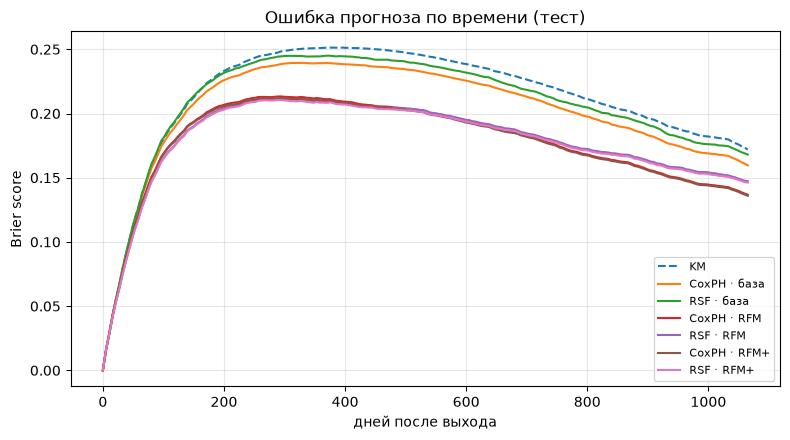

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (set_name, model), S in PRED.items():
    bs = svm.ibs_remain(y_tr, y_te, np.clip(S.astype(np.float64), 1e-12, 1.0), GRID, axis=1)
    ax.plot(GRID, bs, label=f"{model} · {set_name}" if model != "KM" else "KM",
            ls="--" if model == "KM" else "-", lw=1.5)
ax.set_xlabel("дней после выхода"); ax.set_ylabel("Brier score")
ax.set_title("Ошибка прогноза по времени (тест)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "6_ibs_by_time.png", dpi=150); plt.show()

### 4.3. Признаки до 2013

Набор **RFM+ и до 2013** = RFM+ + история человека до 01.01.2013 (аресты, обвинения, сроки prison). Считается отдельно: таблицы, прогнозы и файл метрик (`7_metrics_pre2013.csv`) свои, результаты разделов 3–4 не меняются. Для сравнения в таблице повторены строки RFM+.

Данные до 2013 неполные: jail в базе только с 2013 года, а аресты, обвинения и prison — с 1960–1970-х. Использовать ли их в итоговой модели — вопрос к руководителю.

In [15]:
# Признаки до 2013 - отдельно от наборов разделов 2-4, чтобы не смешивать с результатами выше: свои таблицы tr43 / te43,
# свой прогноз PRED43, свой файл метрик. Общее с разделами 3-4: разбиение, сетка GRID, параметры моделей, функция evaluate.
# Только то, что известно до 01.01.2013 - раньше любого выхода в окне, поэтому подсказки из будущего нет.
# У человека признаки одинаковые во всех его эпизодах:
#   log_n_arrests_pre2013   - log(1 + арестов «человек + день» до 2013);
#   log_n_charges_pre2013   - log(1 + обвинений до 2013) по дате, когда обвинение известно (как в 2.2а);
#   felony_share_pre2013    - доля felony среди этих обвинений (обвинений нет - 0);
#   log_prison_pre2013_n    - log(1 + сроков prison с входом до 2013): закончившиеся до 2013 и начальные (шли на 01.01.2013);
#   log_prison_pre2013_days - log(1 + дней в этих сроках до 01.01.2013);
#   no_history_pre2013      - 1, если до 2013 нет ни арестов, ни обвинений, ни prison.
PRE = pd.Timestamp("2013-01-01")
assert (fr["out_custody"] >= PRE).all(), "выход раньше 2013: признаки до 2013 были бы не только прошлым"
people = pd.Index(fr["id"].unique(), name="id")

# аресты (ar из 2.1) и обвинения (chg из 2.2а, с датой known) до 2013; степень обвинения - из charge
n_ar_pre = ar[ar["last_arrest"] < PRE].groupby("id").size()
with sqlite3.connect(DB) as con:
    degr = pd.read_sql("select person_id id, case_number, charge_number, charge_degree from charge", con)
c_pre = chg[chg["known"] < PRE].merge(degr.drop_duplicates(["id", "case_number", "charge_number"]),
                                      on=["id", "case_number", "charge_number"], how="left", validate="m:1")
n_ch_pre = c_pre.groupby("id").size()
fel_pre = c_pre["charge_degree"].str.startswith("(F", na=False).groupby(c_pre["id"]).mean()

# prison до 2013: закончившиеся до 2013 и начальные; дни - до 01.01.2013
pb = pd.concat([pd.read_csv(SRC / f, usecols=["person_id", "in_custody", "out_custody"], encoding="utf-8-sig",
                            parse_dates=["in_custody", "out_custody"]) for f in ("prison_before_2013.csv", "start_prisons.csv")])
pb = pb[pb["in_custody"] < PRE].copy()
pb["days"] = (pb["out_custody"].clip(upper=PRE) - pb["in_custody"]).dt.days.clip(lower=0)
pg = pb.groupby("person_id")

pre = pd.DataFrame(index=people)
pre["n_arrests_pre2013"] = n_ar_pre.reindex(people, fill_value=0)
pre["n_charges_pre2013"] = n_ch_pre.reindex(people, fill_value=0)
pre["felony_share_pre2013"] = fel_pre.reindex(people).fillna(0.0)
pre["prison_pre2013_n"] = pg.size().reindex(people, fill_value=0)
pre["prison_pre2013_days"] = pg["days"].sum().reindex(people, fill_value=0)
for c in ["n_arrests_pre2013", "n_charges_pre2013", "prison_pre2013_n", "prison_pre2013_days"]:
    pre[f"log_{c}"] = np.log1p(pre[c])
pre["no_history_pre2013"] = ((pre["n_arrests_pre2013"] == 0) & (pre["n_charges_pre2013"] == 0)
                             & (pre["prison_pre2013_n"] == 0)).astype(int)
PRE_FEAT = ["log_n_arrests_pre2013", "log_n_charges_pre2013", "felony_share_pre2013",
            "log_prison_pre2013_n", "log_prison_pre2013_days", "no_history_pre2013"]
print("история до 2013, по людям:")
display(pre[["n_arrests_pre2013", "n_charges_pre2013", "felony_share_pre2013", "prison_pre2013_n", "prison_pre2013_days"]]
        .describe(percentiles=[0.5, 0.9]).T.round(2))
print(f"людей без истории до 2013: {pre['no_history_pre2013'].sum()} из {len(pre)}")

# те же обучение / тест и тот же порядок строк, что в 3.1 (evaluate берёт T, E и te_re оттуда)
tr43 = tr.merge(pre[PRE_FEAT].reset_index(), on="id", how="left", validate="m:1")
te43 = te.merge(pre[PRE_FEAT].reset_index(), on="id", how="left", validate="m:1")
assert (tr43["id"].values == tr["id"].values).all() and (te43["id"].values == te["id"].values).all()
assert not tr43[PRE_FEAT].isna().any().any() and not te43[PRE_FEAT].isna().any().any()

SET43 = "RFM+ и до 2013"
cols43 = FEATURE_SETS["RFM+"] + PRE_FEAT
t1 = _time.time()
PRED43 = {}
cph43 = CoxPHFitter(penalizer=0.1).fit(tr43[cols43 + ["T", "E"]], duration_col="T", event_col="E")
PRED43[(SET43, "CoxPH")] = cph43.predict_survival_function(te43[cols43], times=GRID).values.T
rsf43 = RandomSurvivalForest(**RSF_PARAMS).fit(tr43[cols43].values, Surv.from_arrays(tr43["E"].astype(bool), tr43["T"]))
PRED43[(SET43, "RSF")] = step_on_grid(rsf43.unique_times_, rsf43.predict_survival_function(te43[cols43].values, return_array=True))
print(f"{SET43}: {len(cols43)} признаков, CoxPH + RSF за {_time.time() - t1:.0f} с")

res43 = pd.concat([res.loc[["RFM+"]], pd.DataFrame({k: evaluate(S) for k, S in PRED43.items()}).T.round(4)])
res43.index.names = res.index.names
res43.to_csv(OUT / "7_metrics_pre2013.csv", encoding="utf-8-sig")
print("CoxPH: отношения рисков признаков до 2013 (exp(coef) - на единицу признака)")
display(cph43.summary.loc[PRE_FEAT, ["exp(coef)", "p"]].round(3))
res43

история до 2013, по людям:


,count,mean,std,min,50%,90%,max
n_arrests_pre2013,10329.0,2.78,5.30,0.0,0.0,9.00,63.0
n_charges_pre2013,10329.0,7.74,11.73,0.0,3.0,22.00,151.0
felony_share_pre2013,10329.0,0.13,0.22,0.0,0.0,0.47,1.0
prison_pre2013_n,10329.0,0.31,1.16,0.0,0.0,1.00,15.0
prison_pre2013_days,10329.0,178.87,718.59,0.0,0.0,300.20,10285.0


людей без истории до 2013: 3209 из 10329
RFM+ и до 2013: 36 признаков, CoxPH + RSF за 91 с
CoxPH: отношения рисков признаков до 2013 (exp(coef) - на единицу признака)


,exp(coef),p
covariate,,
log_n_arrests_pre2013,1.179,0.000
log_n_charges_pre2013,1.044,0.001
felony_share_pre2013,1.064,0.233
log_prison_pre2013_n,1.125,0.001
log_prison_pre2013_days,1.014,0.027
no_history_pre2013,0.970,0.336


C-index     IBS   AUPRC  IAUC_RE3
набор признаков модель                                   
RFM+            CoxPH    0.6629  0.1765  0.4491    0.6951
                RSF      0.6717  0.1777  0.4567    0.7005
RFM+ и до 2013  CoxPH    0.6744  0.1734  0.4567    0.7088
                RSF      0.6837  0.1739  0.4634    0.7162

### 4.4. Балл COMPAS

Набор **RFM+, до 2013 и COMPAS** = набор 4.3 + балл COMPAS (шкала «Risk of Recidivism», 1–10). Балл учитывается, только если оценка уже была **на момент выхода**: берётся последняя оценка человека с датой скрининга не позже дня выхода. Если оценки ещё не было, балл заполняется медианой обучения, и ставится флаг `no_compas_known`.

Считается отдельно: таблицы, прогнозы и файл метрик (`8_metrics_compas.csv`) свои, результаты разделов 3–4.3 не меняются. Для сравнения в таблице повторены строки 4.3.

Скрининг COMPAS проводился в 2013–2014 годах, поэтому у части ранних выходов оценки ещё нет.

In [16]:
# Балл COMPAS - отдельно от 4.3, как и 4.3 от наборов выше: свои таблицы tr44 / te44, свой прогноз PRED44, свой файл метрик.
# Берётся шкала «Risk of Recidivism» (decile_score 1-10; -1 - нет оценки, не используется).
# Балл учитывается, только если оценка уже была на момент выхода t0: последняя оценка человека с датой скрининга
# не позже дня выхода. Оценки ещё нет (скрининг позже выхода или его не было) - медиана обучения и флаг no_compas_known.
#   compas_decile    - балл последней известной оценки;
#   no_compas_known  - 1, если на момент выхода оценки ещё не было.
with sqlite3.connect(DB) as con:
    cs = pd.read_sql("select person_id id, screening_date, decile_score from compas "
                     "where type_of_assessment = 'Risk of Recidivism'", con)
cs["screen_day"] = pd.to_datetime(cs["screening_date"], errors="coerce").dt.normalize()
cs = (cs[cs["decile_score"].between(1, 10)].dropna(subset=["screen_day"])
        .sort_values("screen_day").drop_duplicates(["id", "screen_day"], keep="last"))

def add_compas(d):
    """последняя оценка COMPAS с датой скрининга не позже дня выхода; порядок строк d сохраняется"""
    k = d[["id"]].assign(row=np.arange(len(d)), t0=d["out_custody"].dt.normalize()).sort_values("t0")
    k = pd.merge_asof(k, cs[["id", "screen_day", "decile_score"]], left_on="t0", right_on="screen_day", by="id",
                      direction="backward").sort_values("row")
    assert (k["screen_day"].isna() | (k["screen_day"] <= k["t0"])).all(), "оценка COMPAS из будущего"
    return d.assign(compas_decile=k["decile_score"].values.astype(float), compas_screen_day=k["screen_day"].values)

tr44, te44 = add_compas(tr43), add_compas(te43)
COMPAS_FILL = tr44["compas_decile"].median()                                    # медиана обучения
for d in (tr44, te44):
    d["no_compas_known"] = d["compas_decile"].isna().astype(int)
    d["compas_decile"] = d["compas_decile"].fillna(COMPAS_FILL)
COMPAS_FEAT = ["compas_decile", "no_compas_known"]
assert (tr44["id"].values == tr["id"].values).all() and (te44["id"].values == te["id"].values).all()
for name, d in [("обучение", tr44), ("тест", te44)]:
    known = d["no_compas_known"] == 0
    print(f"{name}: оценка известна на момент выхода у {known.mean():.1%} эпизодов, "
          f"средний балл {d.loc[known, 'compas_decile'].mean():.2f}")
print(f"нет оценки - заполнено медианой обучения: {COMPAS_FILL}")

SET44 = "RFM+, до 2013 и COMPAS"
cols44 = cols43 + COMPAS_FEAT
t1 = _time.time()
PRED44 = {}
cph44 = CoxPHFitter(penalizer=0.1).fit(tr44[cols44 + ["T", "E"]], duration_col="T", event_col="E")
PRED44[(SET44, "CoxPH")] = cph44.predict_survival_function(te44[cols44], times=GRID).values.T
rsf44 = RandomSurvivalForest(**RSF_PARAMS).fit(tr44[cols44].values, Surv.from_arrays(tr44["E"].astype(bool), tr44["T"]))
PRED44[(SET44, "RSF")] = step_on_grid(rsf44.unique_times_, rsf44.predict_survival_function(te44[cols44].values, return_array=True))
print(f"{SET44}: {len(cols44)} признаков, CoxPH + RSF за {_time.time() - t1:.0f} с")

res44 = pd.concat([res43, pd.DataFrame({k: evaluate(S) for k, S in PRED44.items()}).T.round(4)])
res44.index.names = res.index.names
res44.to_csv(OUT / "8_metrics_compas.csv", encoding="utf-8-sig")
print("CoxPH: отношения рисков (exp(coef) - на единицу признака)")
display(cph44.summary.loc[COMPAS_FEAT, ["exp(coef)", "p"]].round(3))
res44

обучение: оценка известна на момент выхода у 79.9% эпизодов, средний балл 5.15
тест: оценка известна на момент выхода у 78.7% эпизодов, средний балл 5.09
нет оценки - заполнено медианой обучения: 5.0
RFM+, до 2013 и COMPAS: 38 признаков, CoxPH + RSF за 80 с
CoxPH: отношения рисков (exp(coef) - на единицу признака)


,exp(coef),p
covariate,,
compas_decile,1.079,0.0
no_compas_known,2.150,0.0


C-index     IBS   AUPRC  IAUC_RE3
набор признаков        модель                                   
RFM+                   CoxPH    0.6629  0.1765  0.4491    0.6951
                       RSF      0.6717  0.1777  0.4567    0.7005
RFM+ и до 2013         CoxPH    0.6744  0.1734  0.4567    0.7088
                       RSF      0.6837  0.1739  0.4634    0.7162
RFM+, до 2013 и COMPAS CoxPH    0.7020  0.1627  0.4728    0.7577
                       RSF      0.7091  0.1627  0.4776    0.7628

В чём утечка

В базу ProPublica попали только люди, прошедшие скрининг COMPAS в 2013–2014 годах. Скрининг обычно проводят при новом задержании.
Если на момент выхода оценки ещё нет, значит, скрининг у человека впереди. То есть он почти наверняка ещё попадёт в систему, и модель по сути видит будущее.
Проверка на данных это подтверждает:
эпизодов без оценки на момент выхода 4 200, из них 78 % закончились возвратом, а среди эпизодов с оценкой — 46 %;
в 1 215 случаях скрининг прошёл в течение нескольких дней от следующего входа в заключение, то есть само это следующее заключение и было тем задержанием, при котором проводили скрининг.